# Intelligent Agents: Reflex-Based Agents for GridHunt (Multi-agent Environment)

Student Name: [Add your name]

I have used the following AI tools: [list tools]

I understand that my submission needs to be my own work: [your initials]

## Learning Outcomes

* Apply core AI concepts by implementing the agent function for a simple and model-based reflex agents that respond to environmental percepts.
* Practice how the environment and the agent function interact.
* Analyze agent performance through controlled experiments across different environment configurations.

## Instructions

Total Points: 10

Complete this notebook. Use the provided notebook cells and insert additional code and markdown cells as needed. Submit the completely rendered notebook.
### AI Use

Here are some guidelines that will make it easier for you:

* __Don't:__ Rely on AI auto completion. You will waste a lot of time trying to figure out how the suggested code relates to what we do in class. Turn off AI code completion (e.g., Copilot) in your IDE.
* __Don't:__ Do not submit code/text that you do not understand or have not checked to make sure that it is complete and correct.
* __Do:__ Use AI for debugging and letting it explain code and concepts from class.

## Introduction

![GridHunt Image](gridhunt.png)

Gridhunt is a small educational game that helps you practice implementing simple agent functions. It is a modified Python reimplementation of Gridhunt2.

The objective of gridhunt is to implement an intelligent agent, the hunter, who can catch a monster faster than all other hunters. Gridhunt uses a $n \times n$ arena consisting of a grid of tiles. Gridhunt is a turn-based game, and several hunter agents and the monster agent move around in the arena. A hunter catches the monster if she/he moves on the same square the monster currently occupies. The hunters compete fow who catches the monster first. If the monster survives the maximum number of steps for the game, then the monster wins.

## PEAS Description of Gridhunt

__Performance Measure:__ The performance is measured as the number of steps the hunter uses to catch the monster. Catching the monster means to be on the same square.

__Environment:__ An arena with $n \times n$ squares. At the beginning the monster and the hunters are randomly placed in the arena environment. The hunters and the monster
    can move around, but cannot leave the arena. Since there are three agents involved, this is a competitive multi-agent environment.

__Actuators:__ The agent can move to an adjacent square using actions "north", "east", "west", and "south", or teleport which will move the agent
    to a random square in the arena.

__Sensors:__ The agent can always see its location in the arena and the location of the monster.  

## The Arena Environment

The environment manages the location of the agents (hunter and monster). It initially places them in a random location and then provides them in every step with percepts (the location of the hunter and the monster) and asks them for their action.

__A Note on positions:__
The arena is implemented as an array with row and column indices representing the position.
Positions are stored in a numpy array where `pos[0]` is the row index and `pos[1]` is the column index in the arena. North means up in this array, that is the row index gets smaller when going north. Remember indices in Python start with 0 and go to `n-1`.

In [72]:
import numpy as np
from IPython.display import clear_output
from time import sleep

def arena_environment(hunter_1_agent_function, hunter_2_agent_function, monster_agent_function, n = 30, max_steps = 100, visualize = False, animation = False):
    """
    Simulate an arena where two hunter agent tries to catch a monster agent.

    Parameters:
    hunter_1_agent_function and hunter_2_agent_function (function): A function that takes the current positions of the hunter and monster
                                      and returns the next move for the hunter ('north', 'east', 'west', 'south', 'teleport').
    monster_agent_function (function): A function that takes the current positions of the hunter and monster
                                       and returns the next move for the monster (or 'stay' to remain in place).
    n (int): The size of the arena (n x n grid).
    max_steps (int): The maximum number of steps to simulate.
    visualize (bool): Whether to visualize the arena.
    animation (bool): Whether to animate the visualization with a delay.

    Returns:
    int: The number of steps taken for the hunter to catch the monster or np.nan (not a number) if not caught.
    """

    # Initialize positions
    monster_pos = np.random.randint(0, n-1, size=2)
    hunter_1_pos = np.random.randint(0, n-1, size=2)
    while np.array_equal(hunter_1_pos, monster_pos):
        hunter_1_pos = np.random.randint(0, n-1, size=2)
    hunter_2_pos = np.random.randint(0, n-1, size=2)
    while np.array_equal(hunter_2_pos, monster_pos):
        hunter_2_pos = np.random.randint(0, n-1, size=2)

    def move(action, position):
        """calculate new position for the agent."""
        if action == 'north':
            position[0] -= 1
        elif action == 'south':
            position[0] += 1
        elif action == 'west':
            position[1] -= 1
        elif action == 'east':
            position[1] += 1
        else:
            raise ValueError("Invalid action.")

        # Ensure position stays within bounds
        position = np.clip(position, 0, n-1)
        return position

    def print_arena():

        if animation:
            sleep(1)
            clear_output(wait=True)
        print(f"Step {step}:")
        print(f"Hunter 1 is at '{hunter_1_pos}'; Hunter 2 is at '{hunter_2_pos}'; Monster is at '{monster_pos}'\n")
        arena = np.full((n, n), '.', dtype=str)
        arena[monster_pos[0], monster_pos[1]] = 'M'
        arena[hunter_1_pos[0], hunter_1_pos[1]] = '1'
        arena[hunter_2_pos[0], hunter_2_pos[1]] = '2'
        print("\n".join("".join(row) for row in arena))

    for step in range(max_steps):
        if visualize:
            print_arena()

        # Check if hunter has caught the monster
        if np.array_equal(hunter_1_pos, monster_pos):
            if visualize:
                print(f"Hunter 1 caught the monster in {step} steps!")
            return ("1", step)

        if np.array_equal(hunter_2_pos, monster_pos):
            if visualize:
                print(f"Hunter 2 caught the monster in {step} steps!")
            return ("2", step)

        # Get next move from monster agent function
        monster_action = monster_agent_function(monster_pos, hunter_1_pos, hunter_2_pos)
        if monster_action != 'stay':
            monster_pos = move(monster_action, monster_pos)

        # Get next move from hunter agent function
        hunter_1_action = hunter_1_agent_function(hunter_1_pos, monster_pos)
        if hunter_1_action == 'teleport':
            hunter_1_pos = np.random.randint(0, n-1, size=2)
        else:
            hunter_1_pos = move(hunter_1_action, hunter_1_pos)

        hunter_2_action = hunter_2_agent_function(hunter_2_pos, monster_pos)
        if hunter_2_action == 'teleport':
            hunter_2_pos = np.random.randint(0, n-1, size=2)
        else:
            hunter_2_pos = move(hunter_2_action, hunter_2_pos)

        # print the agents' actions
        if visualize:
            print(f"Hunter 1 chose action '{hunter_1_action}'")
            print(f"Hunter 2 chose action '{hunter_2_action}'")
            print(f"Monster chose action '{monster_action}'")
            print("\n" + "="*n + "\n")

    # the hunter failed to catch the monster within max_steps
    if visualize:
        print(f"Monster won by surviving {max_steps} steps.")

    return ("M", np.nan)

I implement the monster here as a simple agent that moves around randomly, but mostly stays in its place. You can use AI to get a detailed explanation of how the following code works.

In [73]:
monster_actions = ["north", "east", "west", "south", "stay"]

def monster_agent_function_simple(monster_pos, hunter_1_pos, hunter_2_pos):
    return np.random.choice(monster_actions, p=[0.125, 0.125, 0.125, 0.125, 0.5])

# The Hunter Agent

Your job is to implement a simple-reflex hunter agent that can catch the monster. Remember, your agent is implemented as an agent function that get percepts and needs to return a valid action. The actions are:

In [74]:
actions = ["north", "east", "west", "south", "teleport"]

## A Simple Example Implementation

Here is a very simple hunter that just runs around randomly and hopes that it bumps into the monster.

In [75]:
def simple_randomized_hunter_agent_function(hunter_location, monster_location):
    return np.random.choice(actions)

Ask the agent for an action.

In [76]:
simple_randomized_hunter_agent_function([0,0], [5,5])

np.str_('north')

## Experimenting With the Agent

We can place the monster and the hunter into the environment and run a simulation by calling the environment function.

In [77]:
hunter_1 = simple_randomized_hunter_agent_function
hunter_2 = simple_randomized_hunter_agent_function

arena_environment(hunter_1,
                  hunter_2,
                  monster_agent_function_simple,
                  n=5, max_steps=5, visualize=True, animation=False)

Step 0:
Hunter 1 is at '[2 0]'; Hunter 2 is at '[2 1]'; Monster is at '[1 2]'

.....
..M..
12...
.....
.....
Hunter 1 chose action 'teleport'
Hunter 2 chose action 'teleport'
Monster chose action 'stay'

=====

Step 1:
Hunter 1 is at '[3 2]'; Hunter 2 is at '[3 3]'; Monster is at '[1 2]'

.....
..M..
.....
..12.
.....
Hunter 1 chose action 'west'
Hunter 2 chose action 'north'
Monster chose action 'east'

=====

Step 2:
Hunter 1 is at '[3 1]'; Hunter 2 is at '[2 3]'; Monster is at '[1 3]'

.....
...M.
...2.
.1...
.....
Hunter 1 chose action 'teleport'
Hunter 2 chose action 'west'
Monster chose action 'stay'

=====

Step 3:
Hunter 1 is at '[2 2]'; Hunter 2 is at '[2 2]'; Monster is at '[1 3]'

.....
...M.
..2..
.....
.....
Hunter 1 chose action 'north'
Hunter 2 chose action 'teleport'
Monster chose action 'south'

=====

Step 4:
Hunter 1 is at '[1 2]'; Hunter 2 is at '[2 0]'; Monster is at '[2 3]'

.....
..1..
2..M.
.....
.....
Hunter 1 chose action 'east'
Hunter 2 chose action 'teleport

('M', nan)

Well, this was one run, maybe it was just good or bad luck this time!

Let's run an experiment with 100 runs in a $20 \times 20$ arena.  

In [78]:
hunter_1 = simple_randomized_hunter_agent_function
hunter_2 = simple_randomized_hunter_agent_function

steps = [arena_environment(hunter_1,
                           hunter_2,
                           monster_agent_function_simple,
                           n=20, max_steps=100, visualize=False) for _ in range(100)]
print(steps)

[('M', nan), ('M', nan), ('M', nan), ('M', nan), ('2', 60), ('M', nan), ('M', nan), ('2', 99), ('1', 1), ('M', nan), ('2', 62), ('M', nan), ('M', nan), ('M', nan), ('M', nan), ('1', 8), ('M', nan), ('M', nan), ('1', 27), ('M', nan), ('M', nan), ('M', nan), ('M', nan), ('M', nan), ('2', 82), ('M', nan), ('M', nan), ('M', nan), ('2', 31), ('M', nan), ('M', nan), ('2', 5), ('M', nan), ('M', nan), ('M', nan), ('1', 17), ('1', 34), ('1', 75), ('M', nan), ('M', nan), ('M', nan), ('M', nan), ('M', nan), ('2', 88), ('M', nan), ('1', 79), ('M', nan), ('M', nan), ('1', 51), ('1', 51), ('M', nan), ('M', nan), ('M', nan), ('M', nan), ('M', nan), ('2', 49), ('M', nan), ('M', nan), ('M', nan), ('M', nan), ('M', nan), ('M', nan), ('1', 57), ('1', 57), ('M', nan), ('M', nan), ('M', nan), ('M', nan), ('M', nan), ('M', nan), ('M', nan), ('1', 99), ('M', nan), ('1', 64), ('2', 18), ('1', 10), ('M', nan), ('M', nan), ('M', nan), ('1', 14), ('1', 97), ('M', nan), ('M', nan), ('M', nan), ('M', nan), ('M', n

We just got a list with who one and the number of steps to catch the monster for 100 simulation runs.
Let's analysis the results by counting who won how often.

In [79]:
steps = np.array(steps)

print (f"Hunter 1 won: {np.sum(steps[:,0] == "1")}")
print (f"Hunter 2 won: {np.sum(steps[:,0] == "2")}")
print (f"Monster 1 won: {np.sum(steps[:,0] == "M")}")


Hunter 1 won: 19
Hunter 2 won: 13
Monster 1 won: 68


The random agent in not a very good hunter. You need to implement a better agent function.

# Your Agent Implementation [4 points]

Write a new hunter agent function that chases the monster. Copy the simple randomized hunter function from above and modify it using rules based on the monster's and the hunter's location. Let your hunter compete with the random agent. You can also come up with several different agents and let them compete against each other.

### Strategy 1: Greedy Manhattan Hunter — luôn di chuyển sao cho Manhattan distance tới monster giảm đi.

In [80]:
# ============================================================
# STRATEGY 1: GREEDY MANHATTAN HUNTER
# ============================================================

def greedy_manhattan_hunter(hunter_location, monster_location):
    """
    Simple reflex hunter.

    Strategy:
    - Always move toward the current monster location.
    - Choose the axis with the larger distance first.
    - Each normal movement reduces Manhattan distance by 1.

    Parameters
    ----------
    hunter_location : array-like
        Current [row, column] of the hunter.

    monster_location : array-like
        Current [row, column] of the monster.

    Returns
    -------
    str
        One of: north, east, west, south.
    """

    hunter = np.asarray(hunter_location)
    monster = np.asarray(monster_location)

    # Difference between monster and hunter
    row_diff = int(monster[0] - hunter[0])
    col_diff = int(monster[1] - hunter[1])

    # --------------------------------------------------------
    # Move along the dimension with the larger distance first
    # --------------------------------------------------------
    if abs(row_diff) >= abs(col_diff) and row_diff != 0:

        if row_diff > 0:
            return "south"
        else:
            return "north"

    if col_diff != 0:

        if col_diff > 0:
            return "east"
        else:
            return "west"

    # Fallback if only vertical distance remains
    if row_diff != 0:

        if row_diff > 0:
            return "south"
        else:
            return "north"

    # Normally the environment will detect capture before
    # asking for another action.
    return "north"

### Strategy 2: Adaptive Teleport Hunter — nếu monster quá xa thì thử teleport; sau khi đủ gần thì quay lại chiến lược Manhattan chase.

In [81]:
# ============================================================
# STRATEGY 2: ADAPTIVE TELEPORT + MANHATTAN CHASE
# ============================================================

def make_adaptive_teleport_hunter(n, teleport_threshold=None):
    """
    Create a hunter that combines teleportation with
    Manhattan-distance chasing.

    Strategy:
    - If the monster is extremely far away, use teleport.
    - Otherwise, chase the monster using Manhattan distance.

    Parameters
    ----------
    n : int
        Arena size n x n.

    teleport_threshold : int or None
        Manhattan distance above which teleport is used.
        Default = n.

    Returns
    -------
    function
        Hunter agent function.
    """

    if teleport_threshold is None:
        teleport_threshold = n

    def adaptive_teleport_hunter(
        hunter_location,
        monster_location
    ):

        hunter = np.asarray(hunter_location)
        monster = np.asarray(monster_location)

        row_diff = int(
            monster[0] - hunter[0]
        )

        col_diff = int(
            monster[1] - hunter[1]
        )

        # Manhattan distance
        distance = (
            abs(row_diff)
            + abs(col_diff)
        )

        # ----------------------------------------------------
        # TELEPORT:
        # Only use it if the monster is very far away.
        # ----------------------------------------------------
        if distance > teleport_threshold:
            return "teleport"

        # ----------------------------------------------------
        # Otherwise use normal greedy chase.
        # ----------------------------------------------------
        if abs(row_diff) >= abs(col_diff) and row_diff != 0:

            if row_diff > 0:
                return "south"
            else:
                return "north"

        if col_diff != 0:

            if col_diff > 0:
                return "east"
            else:
                return "west"

        if row_diff != 0:

            if row_diff > 0:
                return "south"
            else:
                return "north"

        return "north"

    return adaptive_teleport_hunter

Test nhanh Strategy 1

In [82]:
hunter_1 = greedy_manhattan_hunter
hunter_2 = simple_randomized_hunter_agent_function

arena_environment(
    hunter_1,
    hunter_2,
    monster_agent_function_simple,
    n=10,
    max_steps=50,
    visualize=True,
    animation=False
)

Step 0:
Hunter 1 is at '[0 2]'; Hunter 2 is at '[3 0]'; Monster is at '[6 8]'

..1.......
..........
..........
2.........
..........
..........
........M.
..........
..........
..........
Hunter 1 chose action 'south'
Hunter 2 chose action 'east'
Monster chose action 'stay'


Step 1:
Hunter 1 is at '[1 2]'; Hunter 2 is at '[3 1]'; Monster is at '[6 8]'

..........
..1.......
..........
.2........
..........
..........
........M.
..........
..........
..........
Hunter 1 chose action 'east'
Hunter 2 chose action 'east'
Monster chose action 'north'


Step 2:
Hunter 1 is at '[1 3]'; Hunter 2 is at '[3 2]'; Monster is at '[5 8]'

..........
...1......
..........
..2.......
..........
........M.
..........
..........
..........
..........
Hunter 1 chose action 'south'
Hunter 2 chose action 'south'
Monster chose action 'south'


Step 3:
Hunter 1 is at '[2 3]'; Hunter 2 is at '[4 2]'; Monster is at '[6 8]'

..........
..........
...1......
..........
..2.......
..........
........M.
........

('1', 10)

Test Strategy 2

In [83]:
hunter_1 = make_adaptive_teleport_hunter(
    n=10
)

hunter_2 = simple_randomized_hunter_agent_function

arena_environment(
    hunter_1,
    hunter_2,
    monster_agent_function_simple,
    n=10,
    max_steps=50,
    visualize=True,
    animation=False
)

Step 0:
Hunter 1 is at '[1 6]'; Hunter 2 is at '[0 1]'; Monster is at '[6 8]'

.2........
......1...
..........
..........
..........
..........
........M.
..........
..........
..........
Hunter 1 chose action 'south'
Hunter 2 chose action 'west'
Monster chose action 'stay'


Step 1:
Hunter 1 is at '[2 6]'; Hunter 2 is at '[0 0]'; Monster is at '[6 8]'

2.........
..........
......1...
..........
..........
..........
........M.
..........
..........
..........
Hunter 1 chose action 'south'
Hunter 2 chose action 'west'
Monster chose action 'west'


Step 2:
Hunter 1 is at '[3 6]'; Hunter 2 is at '[0 0]'; Monster is at '[6 7]'

2.........
..........
..........
......1...
..........
..........
.......M..
..........
..........
..........
Hunter 1 chose action 'south'
Hunter 2 chose action 'teleport'
Monster chose action 'north'


Step 3:
Hunter 1 is at '[4 6]'; Hunter 2 is at '[2 3]'; Monster is at '[5 7]'

..........
..........
...2......
..........
......1...
.......M..
..........
.....

('1', 6)

# Your Experiments [2 points]

Copy the simulation code from above and run experiments with your agent.
Experiment with larger arenas of at least size $30 \times 30$.

In [84]:
# ============================================================
# EXPERIMENT HELPER
# ============================================================

import pandas as pd


def run_competition(
    agent_a,
    agent_b,
    agent_a_name,
    agent_b_name,
    n,
    runs=100,
    max_steps=100,
    seed=2026
):
    """
    Compare two hunter strategies.

    To reduce bias caused by Hunter 1 / Hunter 2 ordering,
    Agent A and Agent B alternate positions between runs.

    Parameters
    ----------
    agent_a, agent_b : function
        Hunter agent functions.

    agent_a_name, agent_b_name : str
        Names used in the final result.

    n : int
        Arena size.

    runs : int
        Number of simulations.

    max_steps : int
        Maximum number of steps per game.

    seed : int
        Seed for reproducibility.

    Returns
    -------
    dict
        Competition statistics.
    """

    # Separate random generator used only to create episode seeds
    rng = np.random.RandomState(seed)

    wins_a = 0
    wins_b = 0
    monster_wins = 0

    steps_a = []
    steps_b = []

    for run in range(runs):

        # Reproducible but different seed for every episode
        episode_seed = int(
            rng.randint(0, 2**31 - 1)
        )

        np.random.seed(
            episode_seed
        )

        # ----------------------------------------------------
        # Alternate agent order.
        #
        # Even run:
        #   Hunter 1 = Agent A
        #   Hunter 2 = Agent B
        #
        # Odd run:
        #   Hunter 1 = Agent B
        #   Hunter 2 = Agent A
        # ----------------------------------------------------
        if run % 2 == 0:

            winner, steps = arena_environment(
                agent_a,
                agent_b,
                monster_agent_function_simple,
                n=n,
                max_steps=max_steps,
                visualize=False
            )

            if winner == "1":
                wins_a += 1
                steps_a.append(steps)

            elif winner == "2":
                wins_b += 1
                steps_b.append(steps)

            else:
                monster_wins += 1

        else:

            winner, steps = arena_environment(
                agent_b,
                agent_a,
                monster_agent_function_simple,
                n=n,
                max_steps=max_steps,
                visualize=False
            )

            if winner == "1":
                wins_b += 1
                steps_b.append(steps)

            elif winner == "2":
                wins_a += 1
                steps_a.append(steps)

            else:
                monster_wins += 1

    # --------------------------------------------------------
    # Statistics
    # --------------------------------------------------------
    average_steps_a = (
        np.mean(steps_a)
        if len(steps_a) > 0
        else np.nan
    )

    average_steps_b = (
        np.mean(steps_b)
        if len(steps_b) > 0
        else np.nan
    )

    return {
        "Arena": f"{n}x{n}",

        "Agent A":
            agent_a_name,

        "Agent B":
            agent_b_name,

        "Agent A Wins":
            wins_a,

        "Agent B Wins":
            wins_b,

        "Monster Wins":
            monster_wins,

        "Agent A Win Rate (%)":
            100 * wins_a / runs,

        "Agent B Win Rate (%)":
            100 * wins_b / runs,

        "Avg Steps A":
            average_steps_a,

        "Avg Steps B":
            average_steps_b
    }

### Experiment 1 — Greedy Hunter vs Random Hunter
Arena 20×20

In [85]:
greedy_vs_random_20 = run_competition(
    agent_a=greedy_manhattan_hunter,

    agent_b=
        simple_randomized_hunter_agent_function,

    agent_a_name=
        "Greedy Manhattan",

    agent_b_name=
        "Random Hunter",

    n=20,

    runs=100,

    max_steps=100,

    seed=2026
)

greedy_vs_random_20

{'Arena': '20x20',
 'Agent A': 'Greedy Manhattan',
 'Agent B': 'Random Hunter',
 'Agent A Wins': 97,
 'Agent B Wins': 3,
 'Monster Wins': 0,
 'Agent A Win Rate (%)': 97.0,
 'Agent B Win Rate (%)': 3.0,
 'Avg Steps A': np.float64(12.195876288659793),
 'Avg Steps B': np.float64(10.666666666666666)}

Arena 30×30

In [86]:
greedy_vs_random_30 = run_competition(
    agent_a=greedy_manhattan_hunter,

    agent_b=
        simple_randomized_hunter_agent_function,

    agent_a_name=
        "Greedy Manhattan",

    agent_b_name=
        "Random Hunter",

    n=30,

    runs=100,

    max_steps=100,

    seed=2026
)

greedy_vs_random_30

{'Arena': '30x30',
 'Agent A': 'Greedy Manhattan',
 'Agent B': 'Random Hunter',
 'Agent A Wins': 99,
 'Agent B Wins': 1,
 'Monster Wins': 0,
 'Agent A Win Rate (%)': 99.0,
 'Agent B Win Rate (%)': 1.0,
 'Avg Steps A': np.float64(18.97979797979798),
 'Avg Steps B': np.float64(14.0)}

### Experiment 2 — Adaptive Teleport vs Random

In [87]:
adaptive_20 = make_adaptive_teleport_hunter(
    n=20
)

adaptive_30 = make_adaptive_teleport_hunter(
    n=30
)

In [88]:
teleport_vs_random_20 = run_competition(
    agent_a=adaptive_20,

    agent_b=
        simple_randomized_hunter_agent_function,

    agent_a_name=
        "Adaptive Teleport",

    agent_b_name=
        "Random Hunter",

    n=20,

    runs=100,

    max_steps=100,

    seed=2026
)

In [89]:
teleport_vs_random_30 = run_competition(
    agent_a=adaptive_30,

    agent_b=
        simple_randomized_hunter_agent_function,

    agent_a_name=
        "Adaptive Teleport",

    agent_b_name=
        "Random Hunter",

    n=30,

    runs=100,

    max_steps=100,

    seed=2026
)

### Experiment 3 — Hai strategy đấu trực tiếp
20×20

In [90]:
greedy_vs_teleport_20 = run_competition(
    agent_a=greedy_manhattan_hunter,

    agent_b=adaptive_20,

    agent_a_name=
        "Greedy Manhattan",

    agent_b_name=
        "Adaptive Teleport",

    n=20,

    runs=100,

    max_steps=100,

    seed=2026
)

30x30

In [91]:
greedy_vs_teleport_30 = run_competition(
    agent_a=greedy_manhattan_hunter,

    agent_b=adaptive_30,

    agent_a_name=
        "Greedy Manhattan",

    agent_b_name=
        "Adaptive Teleport",

    n=30,

    runs=100,

    max_steps=100,

    seed=2026
)

In [92]:
results = pd.DataFrame([
    greedy_vs_random_20,
    greedy_vs_random_30,

    teleport_vs_random_20,
    teleport_vs_random_30,

    greedy_vs_teleport_20,
    greedy_vs_teleport_30
])


# Round numerical values for readability
results[
    "Agent A Win Rate (%)"
] = results[
    "Agent A Win Rate (%)"
].round(2)


results[
    "Agent B Win Rate (%)"
] = results[
    "Agent B Win Rate (%)"
].round(2)


results[
    "Avg Steps A"
] = results[
    "Avg Steps A"
].round(2)


results[
    "Avg Steps B"
] = results[
    "Avg Steps B"
].round(2)


results

,Arena,Agent A,Agent B,Agent A Wins,Agent B Wins,Monster Wins,Agent A Win Rate (%),Agent B Win Rate (%),Avg Steps A,Avg Steps B
0,20x20,Greedy Manhattan,Random Hunter,97,3,0,97.0,3.0,12.20,10.67
1,30x30,Greedy Manhattan,Random Hunter,99,1,0,99.0,1.0,18.98,14.00
2,20x20,Adaptive Teleport,Random Hunter,98,2,0,98.0,2.0,11.42,5.00
3,30x30,Adaptive Teleport,Random Hunter,99,1,0,99.0,1.0,16.96,14.00
4,20x20,Greedy Manhattan,Adaptive Teleport,43,57,0,43.0,57.0,9.37,9.77
5,30x30,Greedy Manhattan,Adaptive Teleport,45,55,0,45.0,55.0,13.60,13.84


#### Biểu đồ so sánh Greedy với Random

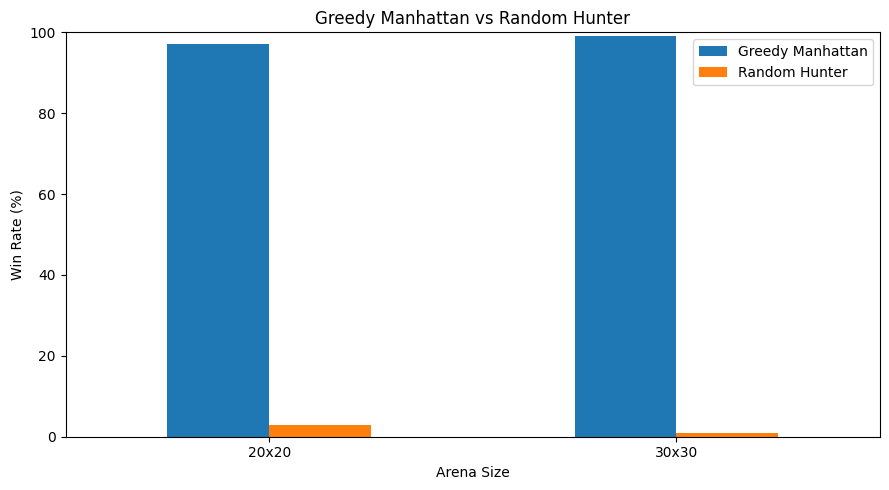

In [93]:
import matplotlib.pyplot as plt


comparison = pd.DataFrame({
    "Arena": [
        "20x20",
        "30x30"
    ],

    "Greedy Manhattan": [
        greedy_vs_random_20[
            "Agent A Win Rate (%)"
        ],

        greedy_vs_random_30[
            "Agent A Win Rate (%)"
        ]
    ],

    "Random Hunter": [
        greedy_vs_random_20[
            "Agent B Win Rate (%)"
        ],

        greedy_vs_random_30[
            "Agent B Win Rate (%)"
        ]
    ]
})


comparison = comparison.set_index(
    "Arena"
)


comparison.plot(
    kind="bar",
    figsize=(9, 5)
)


plt.title(
    "Greedy Manhattan vs Random Hunter"
)

plt.xlabel(
    "Arena Size"
)

plt.ylabel(
    "Win Rate (%)"
)

plt.ylim(
    0,
    100
)

plt.xticks(
    rotation=0
)

plt.tight_layout()

plt.show()

#### Biểu đồ hai strategy của bạn

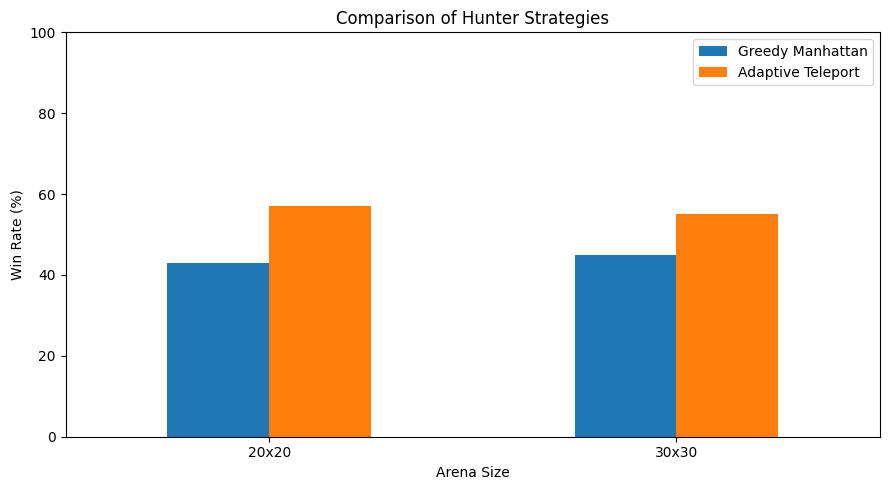

In [94]:
strategy_comparison = pd.DataFrame({
    "Arena": [
        "20x20",
        "30x30"
    ],

    "Greedy Manhattan": [
        greedy_vs_teleport_20[
            "Agent A Win Rate (%)"
        ],

        greedy_vs_teleport_30[
            "Agent A Win Rate (%)"
        ]
    ],

    "Adaptive Teleport": [
        greedy_vs_teleport_20[
            "Agent B Win Rate (%)"
        ],

        greedy_vs_teleport_30[
            "Agent B Win Rate (%)"
        ]
    ]
})


strategy_comparison = (
    strategy_comparison
    .set_index("Arena")
)


strategy_comparison.plot(
    kind="bar",
    figsize=(9, 5)
)


plt.title(
    "Comparison of Hunter Strategies"
)

plt.xlabel(
    "Arena Size"
)

plt.ylabel(
    "Win Rate (%)"
)

plt.ylim(
    0,
    100
)

plt.xticks(
    rotation=0
)

plt.tight_layout()

plt.show()

## Your Conclusion [4 points]

Discuss the following:

* What is your hunter's final strategy to choose actions. Why does it work well?
* Do you use teleportation. Why and in what situation? Why not?
* How does the arena size affects your hunter agent's performance?

Trong thí nghiệm này, tôi đã xây dựng và so sánh hai chiến lược cho Hunter gồm **Greedy Manhattan Hunter** và **Adaptive Teleport Hunter**. Cả hai chiến lược đều sử dụng vị trí hiện tại của Hunter và Monster để lựa chọn hành động thay vì đưa ra quyết định một cách ngẫu nhiên.

Greedy Manhattan Hunter luôn lựa chọn hướng di chuyển sao cho khoảng cách Manhattan giữa Hunter và Monster được giảm xuống. Agent so sánh độ chênh lệch theo hàng và cột, sau đó ưu tiên di chuyển theo chiều có khoảng cách lớn hơn. Chiến lược này hoạt động hiệu quả vì mỗi bước di chuyển thông thường đều hướng Hunter đến gần Monster hơn, thay vì lãng phí lượt cho việc khám phá ngẫu nhiên.

Kết quả thực nghiệm cho thấy Greedy Manhattan Hunter có ưu thế rõ rệt so với Random Hunter. Trong đấu trường 20×20, Greedy Manhattan Hunter thắng 97 trên 100 lần chạy, trong khi Random Hunter chỉ thắng 3 lần. Ở đấu trường lớn hơn 30×30, Greedy Manhattan Hunter thắng 99 trên 100 lần chạy, còn Random Hunter chỉ thắng 1 lần. Kết quả này cho thấy việc sử dụng vị trí hiện tại của Monster để đưa ra các hành động có mục tiêu hiệu quả hơn đáng kể so với chiến lược di chuyển ngẫu nhiên.

Chiến lược thứ hai là Adaptive Teleport Hunter, kết hợp giữa việc truy đuổi trực tiếp theo khoảng cách Manhattan và hành động `teleport`. Khi khoảng cách Manhattan giữa Hunter và Monster lớn hơn kích thước đấu trường \(n\), Hunter sử dụng teleport với mục tiêu tìm được một vị trí ngẫu nhiên có lợi hơn. Khi Monster đã ở đủ gần, Hunter ngừng sử dụng teleport và chuyển sang hành vi truy đuổi trực tiếp tương tự Greedy Manhattan Hunter.

Adaptive Teleport Hunter cũng đạt kết quả rất tốt khi đối đầu với Random Hunter. Trong đấu trường 20×20, chiến lược này thắng 98 trên 100 lần chạy và trong đấu trường 30×30 thắng 99 trên 100 lần chạy. Đáng chú ý hơn, khi hai chiến lược được cho thi đấu trực tiếp với nhau, Adaptive Teleport thắng 57% số trận trong đấu trường 20×20 và 55% trong đấu trường 30×30, trong khi Greedy Manhattan Hunter lần lượt đạt 43% và 45%. Như vậy, trong điều kiện của các thí nghiệm này, việc sử dụng teleport có chọn lọc mang lại một lợi thế cạnh tranh nhỏ so với chiến lược chỉ truy đuổi trực tiếp.

Tuy nhiên, teleport không phải lúc nào cũng mang lại lợi ích vì vị trí sau khi dịch chuyển được lựa chọn ngẫu nhiên. Nếu Hunter đã ở gần Monster, việc teleport có thể khiến Hunter bị đưa đến một vị trí xa hơn và làm mất lợi thế đang có. Vì lý do đó, Adaptive Teleport Hunter không sử dụng teleport liên tục mà chỉ kích hoạt hành động này khi khoảng cách Manhattan vượt quá một ngưỡng được xác định trước. Khi Monster ở gần, Hunter ưu tiên di chuyển thông thường. Do đó, teleport được xem là một hành động có tính đánh đổi giữa rủi ro và lợi ích, thay vì một cách rút ngắn đường đi luôn bảo đảm hiệu quả.

Kích thước đấu trường cũng ảnh hưởng đáng kể đến hiệu năng của các agent. Khi kích thước tăng từ 20×20 lên 30×30, số bước trung bình của Greedy Manhattan Hunter trong các lần thắng khi đối đầu với Random Hunter tăng từ khoảng 12,20 lên 18,98 bước. Tương tự, Adaptive Teleport Hunter tăng từ khoảng 11,42 lên 16,96 bước. Điều này là hợp lý vì khi đấu trường lớn hơn, khoảng cách ban đầu có thể có giữa Hunter và Monster cũng tăng lên, đồng thời không gian tìm kiếm trở nên rộng hơn.

Mặc dù số bước trung bình tăng khi kích thước đấu trường lớn hơn, cả hai chiến lược được xây dựng vẫn duy trì tỷ lệ thắng rất cao. Trong cả sáu thí nghiệm, Monster đều không thể tồn tại đến giới hạn 100 bước. Nhìn chung, kết quả cho thấy việc sử dụng thông tin trạng thái hiện tại của môi trường để lựa chọn hành động có mục tiêu mang lại hiệu quả vượt trội so với hành vi ngẫu nhiên. Trong các chiến lược được thử nghiệm, Adaptive Teleport đạt hiệu quả cạnh tranh trực tiếp cao hơn một chút, trong khi Greedy Manhattan có ưu điểm là đơn giản, dễ giải thích và có hành vi mang tính xác định hơn nhưng vẫn duy trì hiệu suất ổn định.

The monster is also an agent. Describe how the monster's agent function could be changed so it gets better at avoiding the hunter.

Một Monster Agent tốt hơn nên đưa ra quyết định dựa trên vị trí của cả hai Hunter thay vì lựa chọn hành động chủ yếu theo cách ngẫu nhiên. Với mỗi hành động hợp lệ, Monster có thể ước lượng khoảng cách Manhattan sau khi di chuyển tới Hunter 1 và Hunter 2, sau đó ưu tiên hành động giúp nó giữ khoảng cách xa nhất đối với Hunter gần nhất.

Một hàm đánh giá phù hợp là tối đa hóa khoảng cách nhỏ nhất tới hai Hunter. Giả sử vị trí ứng viên của Monster là \(m\), Monster có thể tính khoảng cách Manhattan \(d_1\) tới Hunter 1 và \(d_2\) tới Hunter 2, sau đó chọn hành động làm cực đại giá trị:

\[
\min(d_1, d_2)
\]

Cách tiếp cận này giúp Monster tránh trường hợp di chuyển xa khỏi một Hunter nhưng lại vô tình tiến gần hơn tới Hunter còn lại.

Monster cũng nên tránh các hành động khiến nó cố di chuyển ra ngoài biên của đấu trường. Trong môi trường hiện tại, những hành động như vậy sẽ bị giới hạn bởi biên và gần như làm Monster lãng phí một lượt di chuyển. Hành động `stay` vẫn có thể hữu ích trong một số trường hợp, chẳng hạn khi tất cả các hướng di chuyển hợp lệ đều khiến Monster tiến gần hơn tới một trong hai Hunter. Tuy nhiên, `stay` không nên được lựa chọn với một xác suất cố định cao mà không xét đến trạng thái hiện tại của môi trường.

Cuối cùng, Monster vẫn có thể giữ lại một mức độ ngẫu nhiên nhỏ để tránh việc hành vi trở nên hoàn toàn có thể dự đoán. Ví dụ, trong phần lớn các lượt, Monster có thể chọn hành động an toàn nhất theo hàm đánh giá khoảng cách, nhưng thỉnh thoảng lựa chọn một hành động hợp lệ khác. Cách này sẽ tạo ra một Monster Agent có khả năng né tránh tốt hơn, phản ứng hợp lý hơn với vị trí của hai Hunter, đồng thời vẫn giữ được yếu tố không chắc chắn để bài toán không trở nên quá dễ dự đoán.

# More Work (optional)

* Improve the monster agent so it tries to run away from the hunters. Don;t make the monster too fast or the hunters will never be able to catch it.
* How could the two hunter agents work together? You need to think about information sharing. This can be implemented by the two agent functions sharing a single Python class or the environment could be expanded by an action "shout" that lets the other agent perceive a message.